In [1]:
import sys 
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
PIPELINE_ROOT = Path(
    "/home/rittick-dutta/Desktop/Research/Pipeline2"
)

if str(PIPELINE_ROOT) not in sys.path:
    sys.path.insert(0, str(PIPELINE_ROOT))

DATASET_ROOT = Path(
    "/home/rittick-dutta/Desktop/Research/"
    "symile-mimic/symile-mimic-aws"
)

In [3]:
from utils.data_helper import TARGETS, SymileMIMICDataset, create_dataloaders

In [4]:
print("Pipeline exists:", PIPELINE_ROOT.is_dir())
print("Dataset exists:", DATASET_ROOT.is_dir())

Pipeline exists: True
Dataset exists: True


In [5]:
train_loader, val_loader, test_loader = create_dataloaders(
    dataset_root=DATASET_ROOT,
    batch_size=16,
    train_missing_ratio=0.30,
    val_missing_ratio=0.30,
    test_missing_ratio=0.30,
    num_workers=0,
    seed=42,
)

print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Test samples:", len(test_loader.dataset))

Training samples: 10000
Validation samples: 750
Test samples: 464


In [6]:
batch = next(iter(train_loader))

for name, tensor in batch.items():
    print(f"{name}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")

assert batch["labels"].shape == (batch["cxr"].size(0), len(TARGETS))
assert batch["label_mask"].shape == batch["labels"].shape
print("Prediction targets:", len(TARGETS))
print(TARGETS)

cxr: shape=(16, 3, 320, 320), dtype=torch.float32
ecg: shape=(16, 1, 5000, 12), dtype=torch.float32
labs: shape=(16, 100), dtype=torch.float32
labels: shape=(16, 14), dtype=torch.float32
label_mask: shape=(16, 14), dtype=torch.bool
modality_mask: shape=(16, 3), dtype=torch.bool
hadm_id: shape=(16,), dtype=torch.int64
Prediction targets: 14
['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum', 'Fracture', 'Lung Lesion', 'Lung Opacity', 'No Finding', 'Pleural Effusion', 'Pleural Other', 'Pneumonia', 'Pneumothorax', 'Support Devices']


In [7]:
# Check the known/unknown labels for every target in each clinical split.
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    raw = loader.dataset.raw_labels
    assert loader.dataset.CLASSES == TARGETS
    assert raw.shape == (len(loader.dataset), len(TARGETS))
    assert np.array_equal(loader.dataset.label_masks, np.isin(raw, [0, 1]))
    print(f"{split}: {raw.shape[0]} admissions, {raw.shape[1]} targets")
    display(pd.DataFrame({
        "target": TARGETS,
        "positive": (raw == 1).sum(axis=0),
        "negative": (raw == 0).sum(axis=0),
        "uncertain": (raw == -1).sum(axis=0),
        "unreported": np.isnan(raw).sum(axis=0),
    }))


train: 10000 admissions, 14 targets


,target,positive,negative,uncertain,unreported
0,Atelectasis,2867,118,588,6427
1,Cardiomegaly,3346,886,450,5318
2,Consolidation,741,330,263,8666
3,Edema,2067,1772,834,5327
4,Enlarged Cardiomediastinum,504,265,663,8568
5,Fracture,179,17,12,9792
6,Lung Lesion,285,22,52,9641
7,Lung Opacity,3108,175,223,6494
8,No Finding,1368,0,0,8632
9,Pleural Effusion,3618,1701,371,4310


val: 750 admissions, 14 targets


,target,positive,negative,uncertain,unreported
0,Atelectasis,225,5,43,477
1,Cardiomegaly,268,81,32,369
2,Consolidation,60,22,21,647
3,Edema,148,151,52,399
4,Enlarged Cardiomediastinum,38,20,50,642
5,Fracture,14,1,0,735
6,Lung Lesion,18,0,2,730
7,Lung Opacity,220,13,12,505
8,No Finding,113,0,0,637
9,Pleural Effusion,253,149,27,321


test: 464 admissions, 14 targets


,target,positive,negative,uncertain,unreported
0,Atelectasis,141,5,22,296
1,Cardiomegaly,144,50,20,250
2,Consolidation,29,22,8,405
3,Edema,82,88,39,255
4,Enlarged Cardiomediastinum,28,15,30,391
5,Fracture,10,0,0,454
6,Lung Lesion,12,2,3,447
7,Lung Opacity,131,13,12,308
8,No Finding,69,0,0,395
9,Pleural Effusion,166,90,15,193


## Five admissions from each split
Retrieve samples once so random training masks remain consistent between tables and plots. Tables show original CSV labels and labs. Model inputs use lab percentiles and observation indicators. Hidden CXRs are shown as placeholders. ECG plots use lead indices (names/order not independently verified), scaled amplitude, and sample index.


## Training


In [8]:
train_dataset = train_loader.dataset
train_indices = list(range(min(5, len(train_dataset))))

# Retrieve once; reuse these samples in both plots below.
train_samples = [train_dataset[i] for i in train_indices]
train_table = train_dataset.metadata.iloc[train_indices].copy()
train_table["cxr_available"] = [s["modality_mask"][0].item() for s in train_samples]
assert train_table["hadm_id"].tolist() == [s["hadm_id"].item() for s in train_samples]
print("Training admissions:", len(train_dataset))
with pd.option_context("display.max_columns", None):
    display(train_table)


Training admissions: 10000


,subject_id,hadm_id,cxr_path,Atelectasis,Cardiomegaly,Edema,Lung Opacity,No Finding,Pleural Effusion,ecg_path,51221,51265,50912,50971,51222,51301,51249,51279,51250,51248,51277,51006,50983,50902,50882,50868,50931,50960,50893,50970,51237,51274,51275,51146,51256,51254,51200,51244,52172,50934,51678,50947,50861,50878,50813,50863,50885,50820,50862,50802,50821,50804,50818,52075,52073,52074,52069,51133,50910,52135,51221_percentile,51265_percentile,50912_percentile,50971_percentile,51222_percentile,51301_percentile,51249_percentile,51279_percentile,51250_percentile,51248_percentile,51277_percentile,51006_percentile,50983_percentile,50902_percentile,50882_percentile,50868_percentile,50931_percentile,50960_percentile,50893_percentile,50970_percentile,51237_percentile,51274_percentile,51275_percentile,51146_percentile,51256_percentile,51254_percentile,51200_percentile,51244_percentile,52172_percentile,50934_percentile,51678_percentile,50947_percentile,50861_percentile,50878_percentile,50813_percentile,50863_percentile,50885_percentile,50820_percentile,50862_percentile,50802_percentile,50821_percentile,50804_percentile,50818_percentile,52075_percentile,52073_percentile,52074_percentile,52069_percentile,51133_percentile,50910_percentile,52135_percentile,Consolidation,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Pleural Other,Pneumonia,Pneumothorax,Support Devices,array_index,cxr_available
0,17628012,25296721,files/p17/p17628012/s51943003/a8e58d81-689f98c...,1.0,NaN,1.0,1.0,NaN,1.0,files/p1762/p17628012/s46857043/46857043,36.5,153.0,1.1,4.5,12.5,14.7,34.2,3.90,94.0,32.1,13.1,17.0,139.0,107.0,27.0,10.0,134.0,1.4,8.7,2.7,1.4,15.4,35.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,19.0,1.5,43.0,0.9,7.47,NaN,4.0,236.0,28.0,38.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.543258,0.221542,0.563640,0.677416,0.645913,0.793935,0.863098,0.499799,0.661008,0.820912,0.173162,0.353755,0.656369,0.875176,0.792958,0.042157,0.586866,0.067158,0.518573,0.171893,0.728236,0.713651,0.718674,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.204527,0.172597,0.380863,0.044254,0.750168,0.920958,NaN,0.891749,0.775259,0.740920,0.345366,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,0.0,1.0,0,True
1,11686629,26188372,files/p11/p11686629/s50480565/a2fb7bee-758a13b...,1.0,NaN,-1.0,1.0,NaN,NaN,files/p1168/p11686629/s45321834/45321834,34.5,217.0,1.4,5.5,11.4,16.4,33.2,3.61,96.0,31.7,13.6,55.0,141.0,110.0,22.0,15.0,249.0,2.2,8.7,3.7,0.9,9.5,30.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1,NaN,NaN,7.30,NaN,-1.0,147.0,26.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.433584,0.503313,0.705652,0.911493,0.476702,0.848263,0.675171,0.358578,0.754419,0.772298,0.304540,0.900331,0.829845,0.947078,0.337223,0.428916,0.918345,0.822305,0.518573,0.584818,0.050706,0.006951,0.465979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.164815,NaN,NaN,0.275270,NaN,0.469087,0.663878,0.600484,0.745983,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,1.0,0.0,1.0,1,False
2,14798598,20652011,files/p14/p14798598/s55516445/5e518f88-5192986...,1.0,1.0,-1.0,NaN,NaN,1.0,files/p1479/p14798598/s45042373/45042373,32.2,166.0,10.9,5.1,11.1,8.1,34.4,3.68,87.0,30.1,15.2,58.0,145.0,101.0,27.0,22.0,101.0,2.6,9.4,4.9,NaN,NaN,NaN,0.3,71.6,7.2,3.8,17.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,244.0,NaN,0.314286,0.277153,0.993586,0.856239,0.430006,0.359209,0.887204,0.393632,0.256328,0.519486,0.633286,0.912764,0.970215,0.512553,0.792958,0.923634,0.238996,0.958494,0.841625,0.873562,NaN,NaN,NaN,0.560416,0.312249,0.707969,0.921494,0.680184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.701479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,True
3,12672152,26177106,files/p12/p12672152/s52146889/ff1c767f-4899cef...,NaN,1.0,1.0,1.0,NaN,1.0,files/p1267/p12672152/s45735573/45735573,33.7,589.0,1.8,6.5,9.7,49.3,28.8,3.71,91.0,26.2,15.2,60.0,138.0,109.0,13.0,23.0,141.0,2.1,7.0,6.6,1.6,16.9,53.4,0.0,85.0,7.0,0.0,4.0,NaN,NaN,NaN,NaN,9.0,27.0,8.5,141.0,0.9,7.07,2.3,-19.0,161.0,11.0,37.0,NaN,NaN,NaN,NaN,

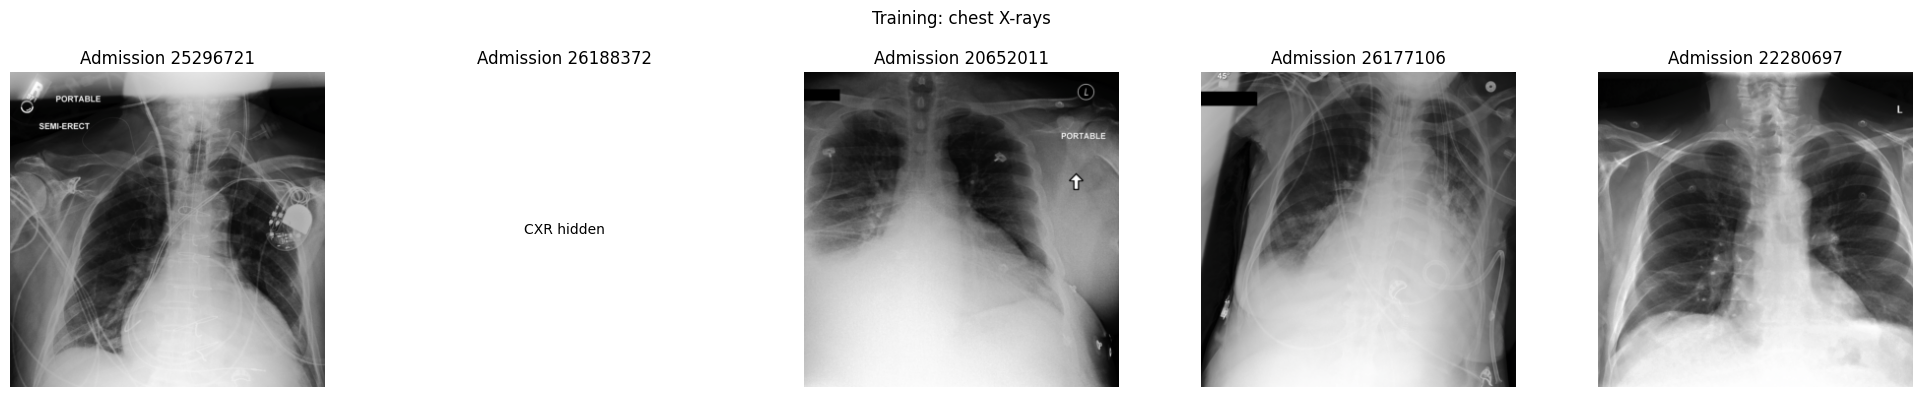

In [9]:
# Undo ImageNet normalization for display only.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(1, len(train_samples), figsize=(20, 4), squeeze=False)
for ax, sample in zip(axes.flat, train_samples):
    if sample["modality_mask"][0].item():
        image = sample["cxr"].numpy().transpose(1, 2, 0)
        ax.imshow(np.clip(image * std + mean, 0, 1))
    else:
        assert not sample["cxr"].any().item()
        ax.text(0.5, 0.5, "CXR hidden", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Admission {sample['hadm_id'].item()}")
    ax.axis("off")
fig.suptitle("Training: chest X-rays")
plt.tight_layout()
plt.show()
plt.close(fig)


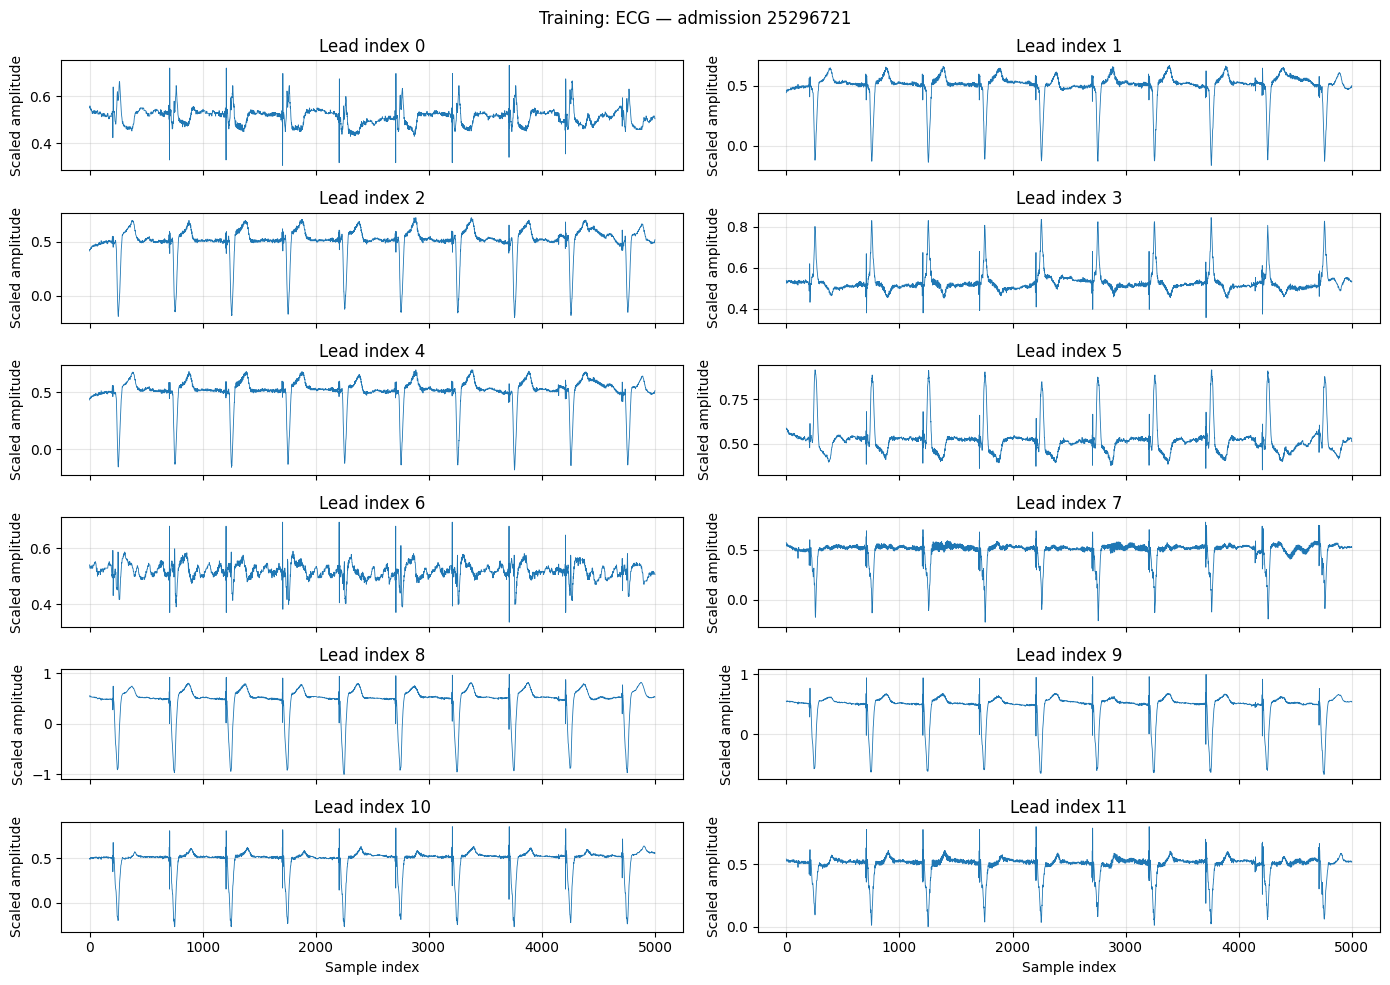

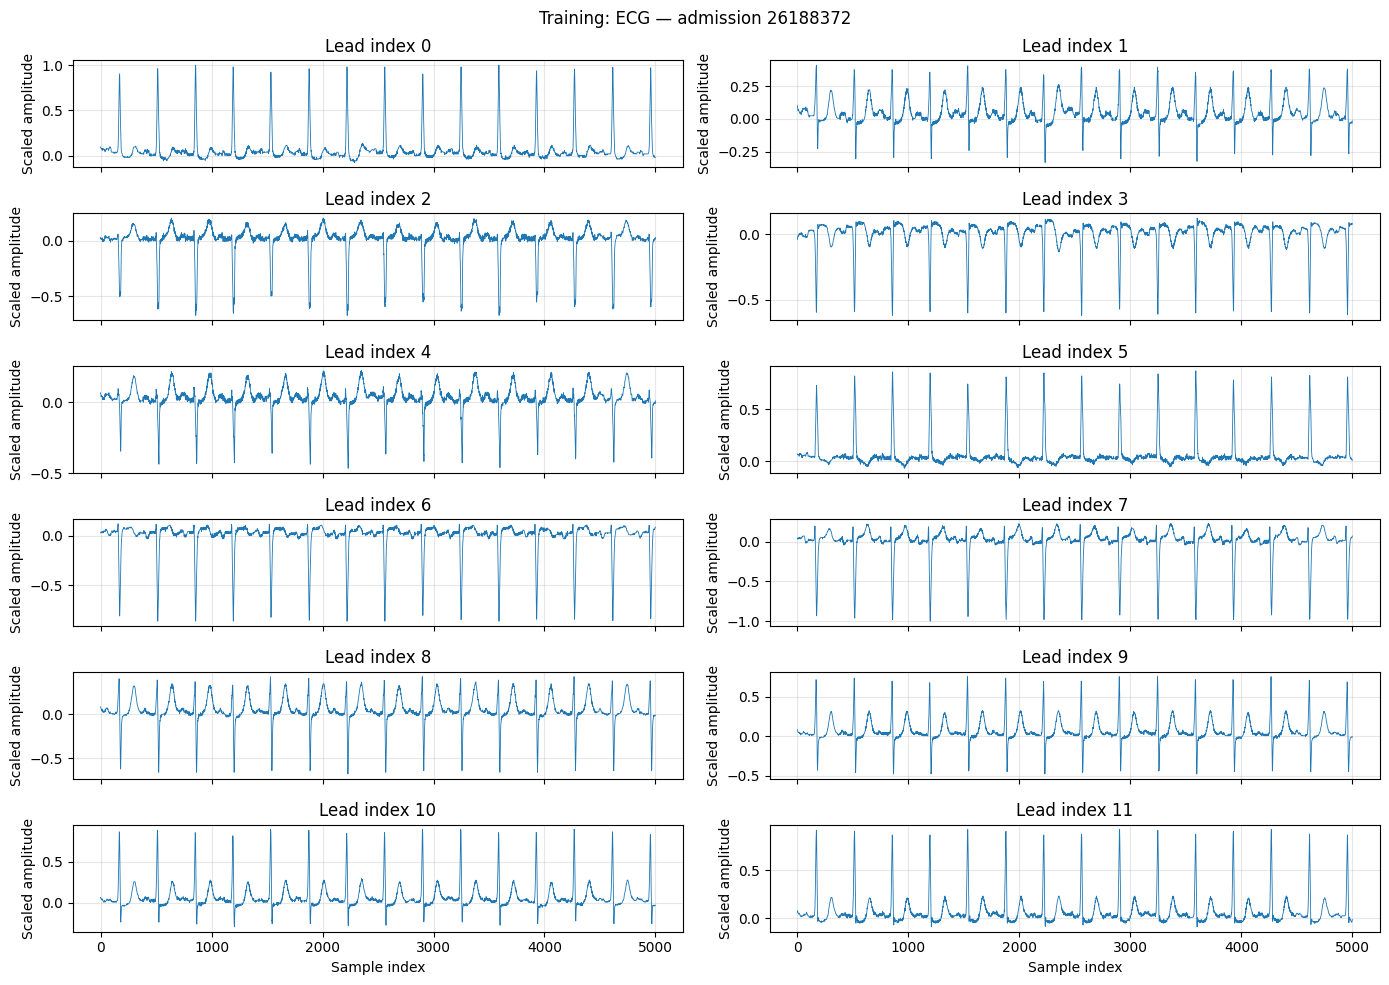

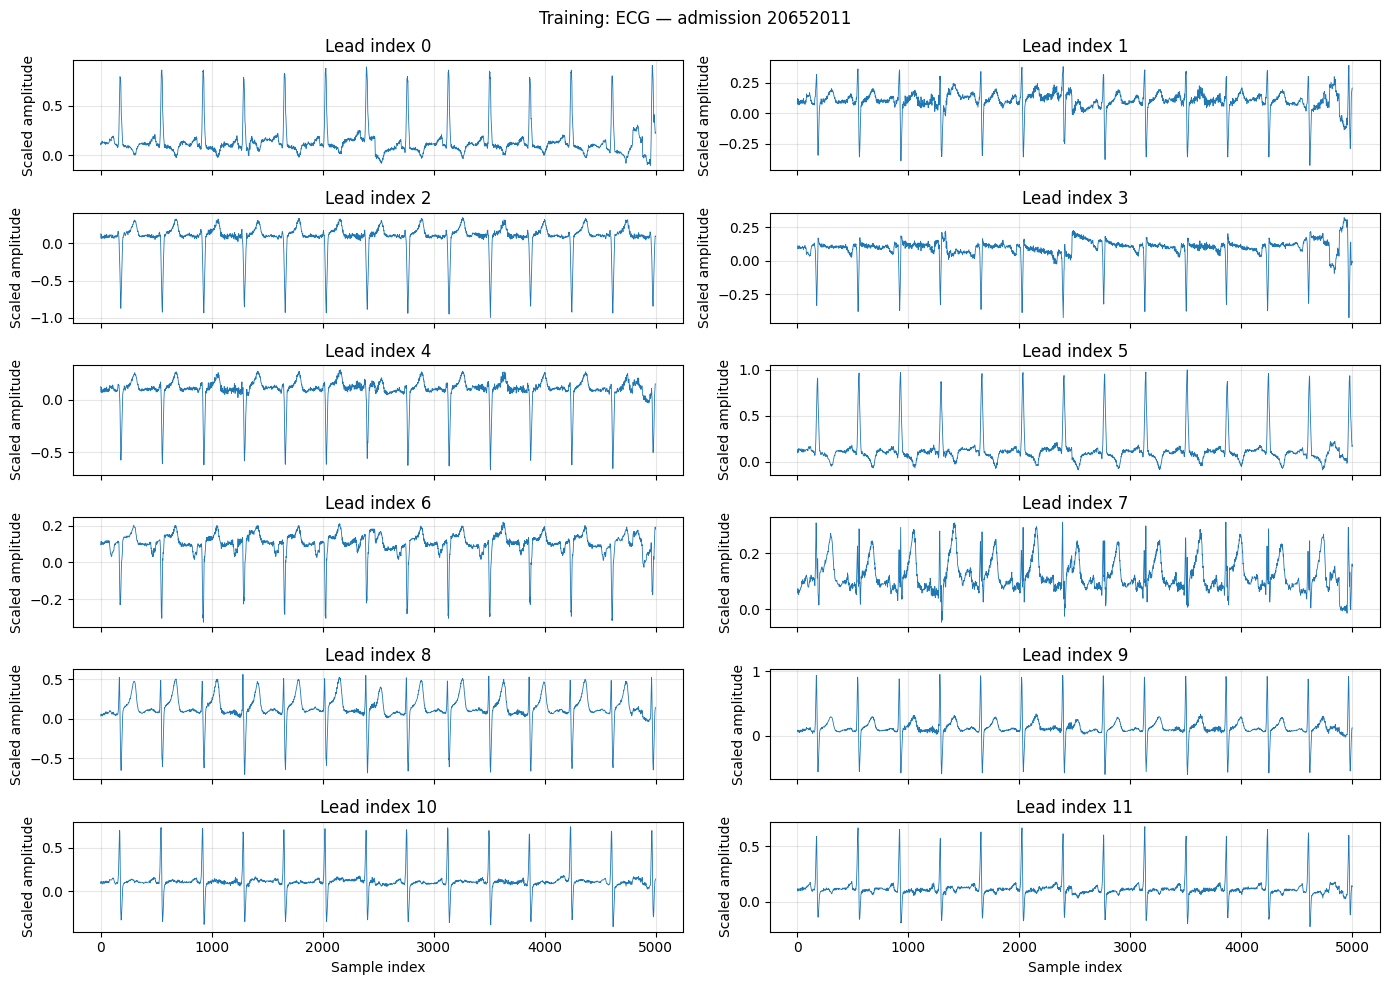

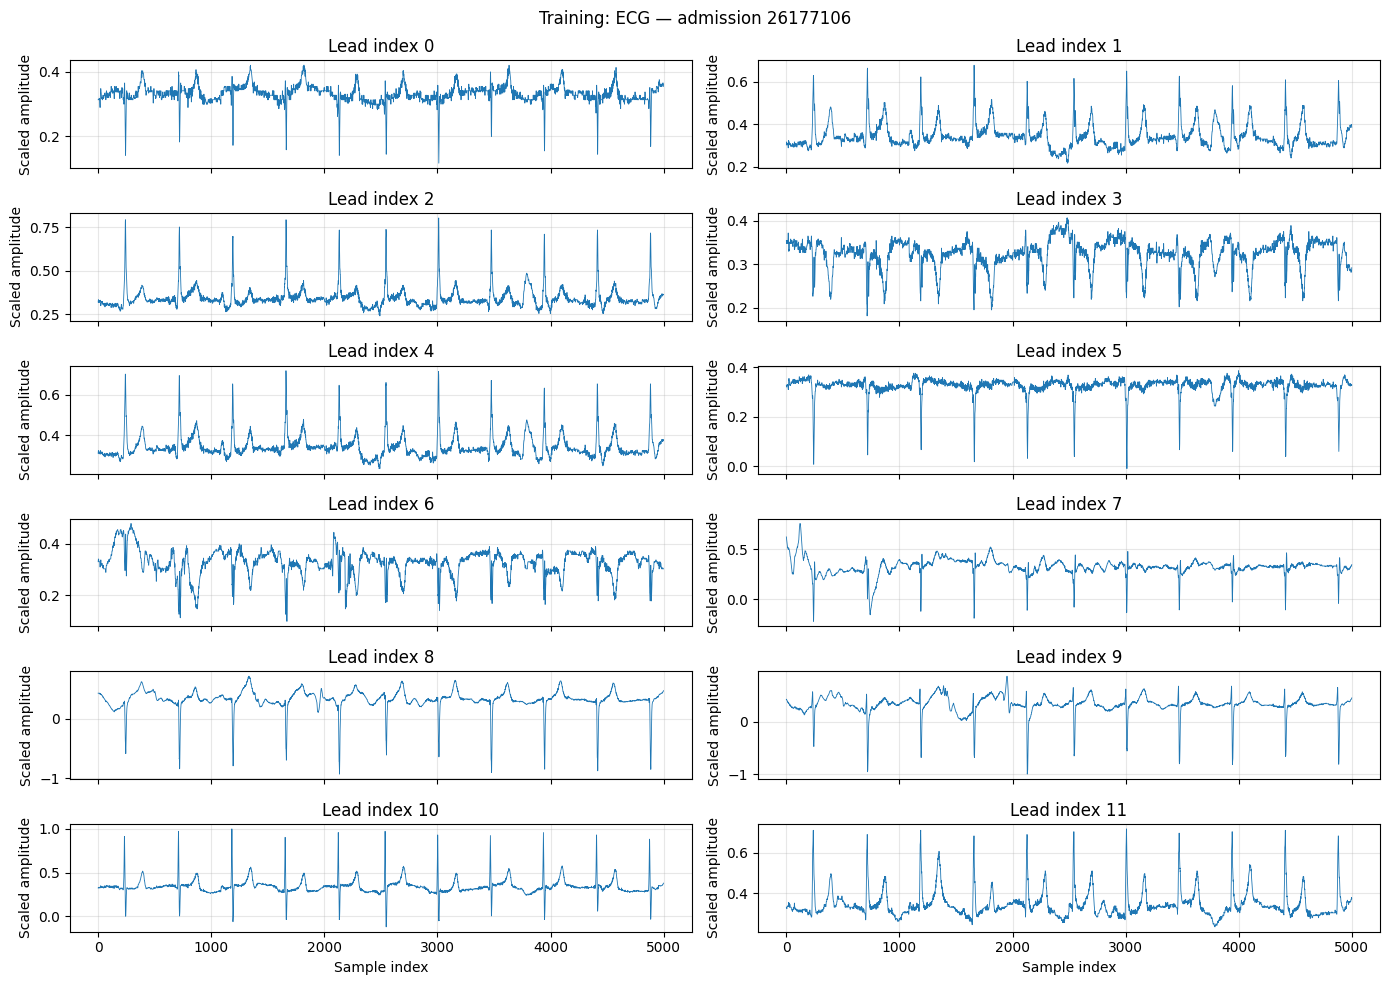

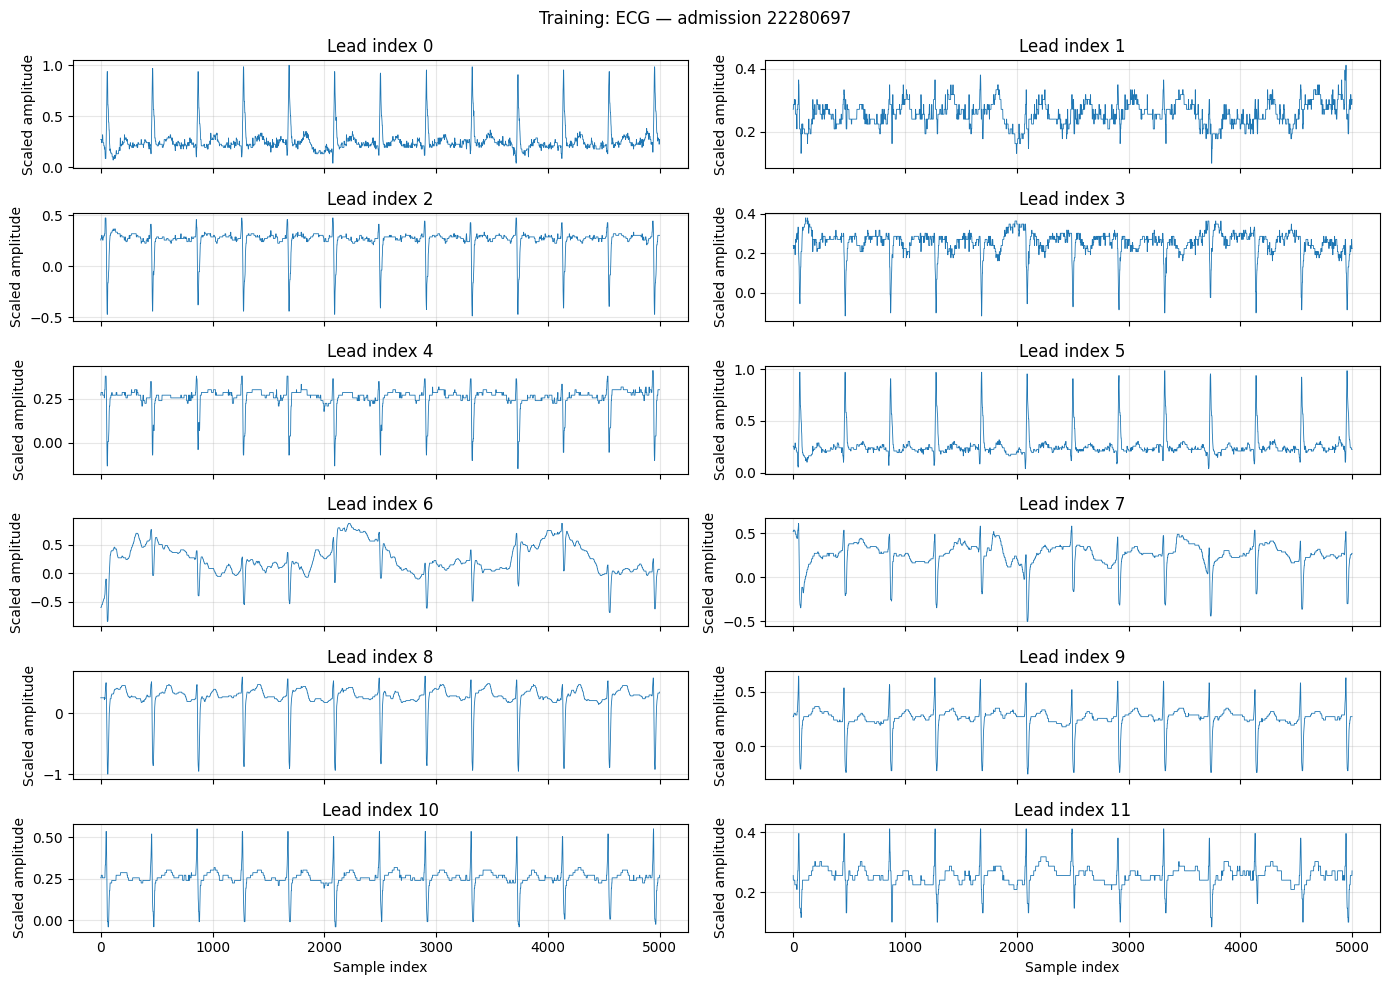

In [10]:
# Display all 12 ECG leads for each of these same five admissions.
for sample in train_samples:
    ecg = sample["ecg"][0].numpy()  # (5000, 12)
    fig, axes = plt.subplots(6, 2, figsize=(14, 10), sharex=True)
    for lead, ax in enumerate(axes.flat):
        ax.plot(ecg[:, lead], linewidth=0.6)
        ax.set_title(f"Lead index {lead}")
        ax.set_ylabel("Scaled amplitude")
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Sample index")
    fig.suptitle(f"Training: ECG — admission {sample['hadm_id'].item()}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## Validation


In [11]:
val_dataset = val_loader.dataset
val_indices = list(range(min(5, len(val_dataset))))

# Retrieve once; reuse these samples in both plots below.
val_samples = [val_dataset[i] for i in val_indices]
val_table = val_dataset.metadata.iloc[val_indices].copy()
val_table["cxr_available"] = [s["modality_mask"][0].item() for s in val_samples]
assert val_table["hadm_id"].tolist() == [s["hadm_id"].item() for s in val_samples]
print("Validation admissions:", len(val_dataset))
with pd.option_context("display.max_columns", None):
    display(val_table)


Validation admissions: 750


,subject_id,hadm_id,cxr_path,Atelectasis,Cardiomegaly,Edema,Lung Opacity,No Finding,Pleural Effusion,ecg_path,51221,51265,50912,50971,51222,51301,51249,51279,51250,51248,51277,51006,50983,50902,50882,50868,50931,50960,50893,50970,51237,51274,51275,51146,51256,51254,51200,51244,52172,50934,51678,50947,50861,50878,50813,50863,50885,50820,50862,50802,50821,50804,50818,52075,52073,52074,52069,51133,50910,52135,51221_percentile,51265_percentile,50912_percentile,50971_percentile,51222_percentile,51301_percentile,51249_percentile,51279_percentile,51250_percentile,51248_percentile,51277_percentile,51006_percentile,50983_percentile,50902_percentile,50882_percentile,50868_percentile,50931_percentile,50960_percentile,50893_percentile,50970_percentile,51237_percentile,51274_percentile,51275_percentile,51146_percentile,51256_percentile,51254_percentile,51200_percentile,51244_percentile,52172_percentile,50934_percentile,51678_percentile,50947_percentile,50861_percentile,50878_percentile,50813_percentile,50863_percentile,50885_percentile,50820_percentile,50862_percentile,50802_percentile,50821_percentile,50804_percentile,50818_percentile,52075_percentile,52073_percentile,52074_percentile,52069_percentile,51133_percentile,50910_percentile,52135_percentile,label_hadm_id,label,Consolidation,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Pleural Other,Pneumonia,Pneumothorax,Support Devices,array_index,cxr_available
0,15509168,20763309,files/p15/p15509168/s53396022/b715591b-1d9ca5a...,1.0,1.0,1.0,NaN,NaN,0.0,files/p1550/p15509168/s41634494/41634494,35.4,432.0,1.3,4.9,10.4,13.8,29.4,3.97,89.0,26.2,15.5,31.0,139.0,100.0,30.0,14.0,149.0,1.8,8.8,3.6,1.0,11.4,31.6,0.7,69.6,7.1,0.4,20.8,50.2,NaN,NaN,NaN,85.0,99.0,1.5,96.0,0.4,7.27,4.0,6.0,35.0,38.0,80.0,9.61,0.06,0.98,0.09,2.88,NaN,1.4,0.484612,0.939972,0.668170,0.816054,0.328881,0.757180,0.043793,0.532644,0.367417,0.099337,0.675974,0.714730,0.656369,0.439546,0.925050,0.309588,0.680967,0.375977,0.570801,0.541056,0.239973,0.251709,0.523009,0.876921,0.269331,0.698629,0.389927,0.770631,0.589847,NaN,NaN,NaN,0.881178,0.845693,0.380863,0.574962,0.396615,0.204492,0.770091,0.938174,0.101475,0.959938,0.963020,0.648917,0.530018,0.718650,0.958792,0.926821,NaN,0.950449,20763309,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0,False
1,17501651,25626780,files/p17/p17501651/s50151328/ebb38a2a-c5a7c36...,-1.0,-1.0,-1.0,NaN,NaN,-1.0,files/p1750/p17501651/s47874812/47874812,27.8,187.0,1.0,4.1,9.4,11.6,33.8,3.00,93.0,31.3,12.8,22.0,138.0,104.0,23.0,15.0,329.0,1.9,8.1,4.8,0.9,10.0,26.8,NaN,NaN,NaN,NaN,NaN,43.5,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,7.41,NaN,0.0,444.0,24.0,36.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.144160,0.367396,0.492383,0.450070,0.202651,0.640189,0.797911,0.146846,0.603556,0.714042,0.109281,0.530833,0.558865,0.732778,0.429376,0.428916,0.967520,0.495651,0.229176,0.861832,0.050706,0.025638,0.170975,NaN,NaN,NaN,NaN,NaN,0.187792,NaN,NaN,NaN,NaN,NaN,0.119353,NaN,NaN,0.724942,NaN,0.660286,0.958618,0.436496,0.267885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25626780,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,1,True
2,18454926,22802263,files/p18/p18454926/s57516984/bf9a461d-895a4a0...,NaN,1.0,1.0,NaN,NaN,1.0,files/p1845/p18454926/s42348835/42348835,44.5,648.0,0.7,4.1,12.1,39.4,27.2,6.54,68.0,18.5,20.6,26.0,137.0,99.0,23.0,19.0,136.0,2.1,8.8,3.1,1.3,13.9,150.0,0.5,92.7,3.3,0.3,1.6,45.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.51,0.13,1.31,0.18,0.63,1513.0,1.6,0.911880,0.989861,0.197234,0.450070,0.585660,0.991866,0.004821,0.998594,0.004419,0.001306,0.969767,0.628196,0.458644,0.368749,0.429376,0.802294,0.599514,0.733898,0.570801,0.321566,0.668528,0.615201,1.000000,0.764720,0.959092,0.183731,0.343817,0.015252,0.312987,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.995385,0.717584,0.871758,0.995737,0.209947,0.928464,0.968390,22802263,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,False
3,15286981,20135568,files/p15/p15286981/s54363418/e0b42aea-be89bb9...,NaN,0.0,0.0,NaN,1.0,0.0,files/p1528/p15286981/s42527962/42527962,31.6,155.0,1.0,3.9,10.1,4.7,3

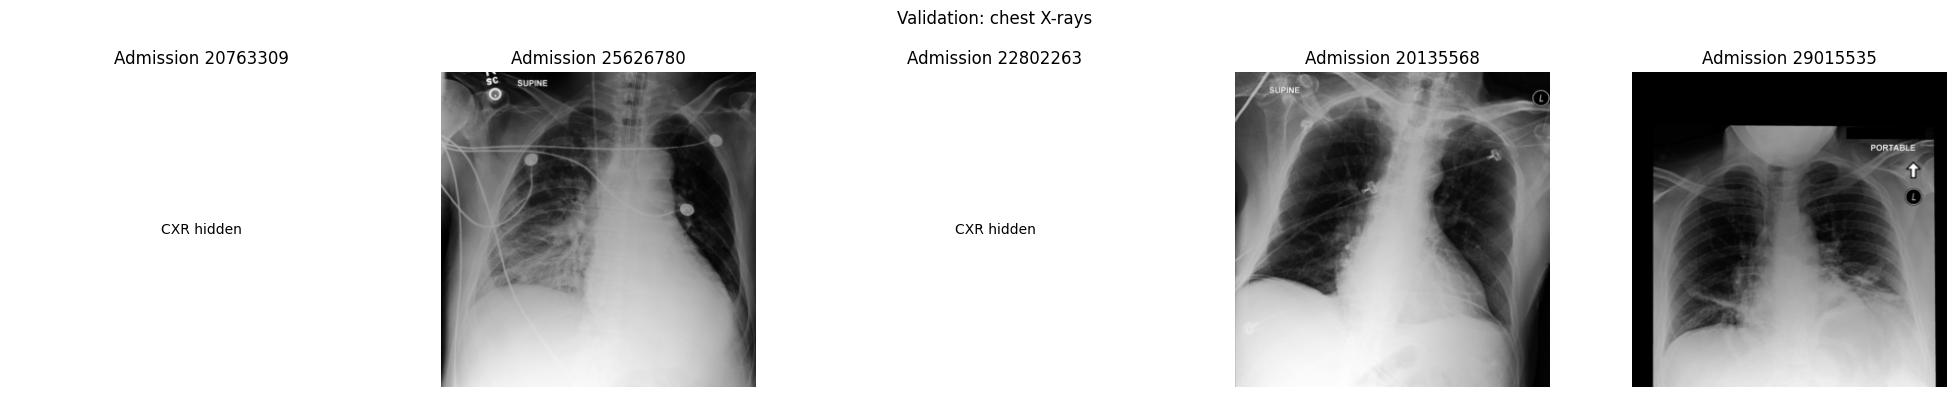

In [12]:
# Undo ImageNet normalization for display only.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(1, len(val_samples), figsize=(20, 4), squeeze=False)
for ax, sample in zip(axes.flat, val_samples):
    if sample["modality_mask"][0].item():
        image = sample["cxr"].numpy().transpose(1, 2, 0)
        ax.imshow(np.clip(image * std + mean, 0, 1))
    else:
        assert not sample["cxr"].any().item()
        ax.text(0.5, 0.5, "CXR hidden", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Admission {sample['hadm_id'].item()}")
    ax.axis("off")
fig.suptitle("Validation: chest X-rays")
plt.tight_layout()
plt.show()
plt.close(fig)


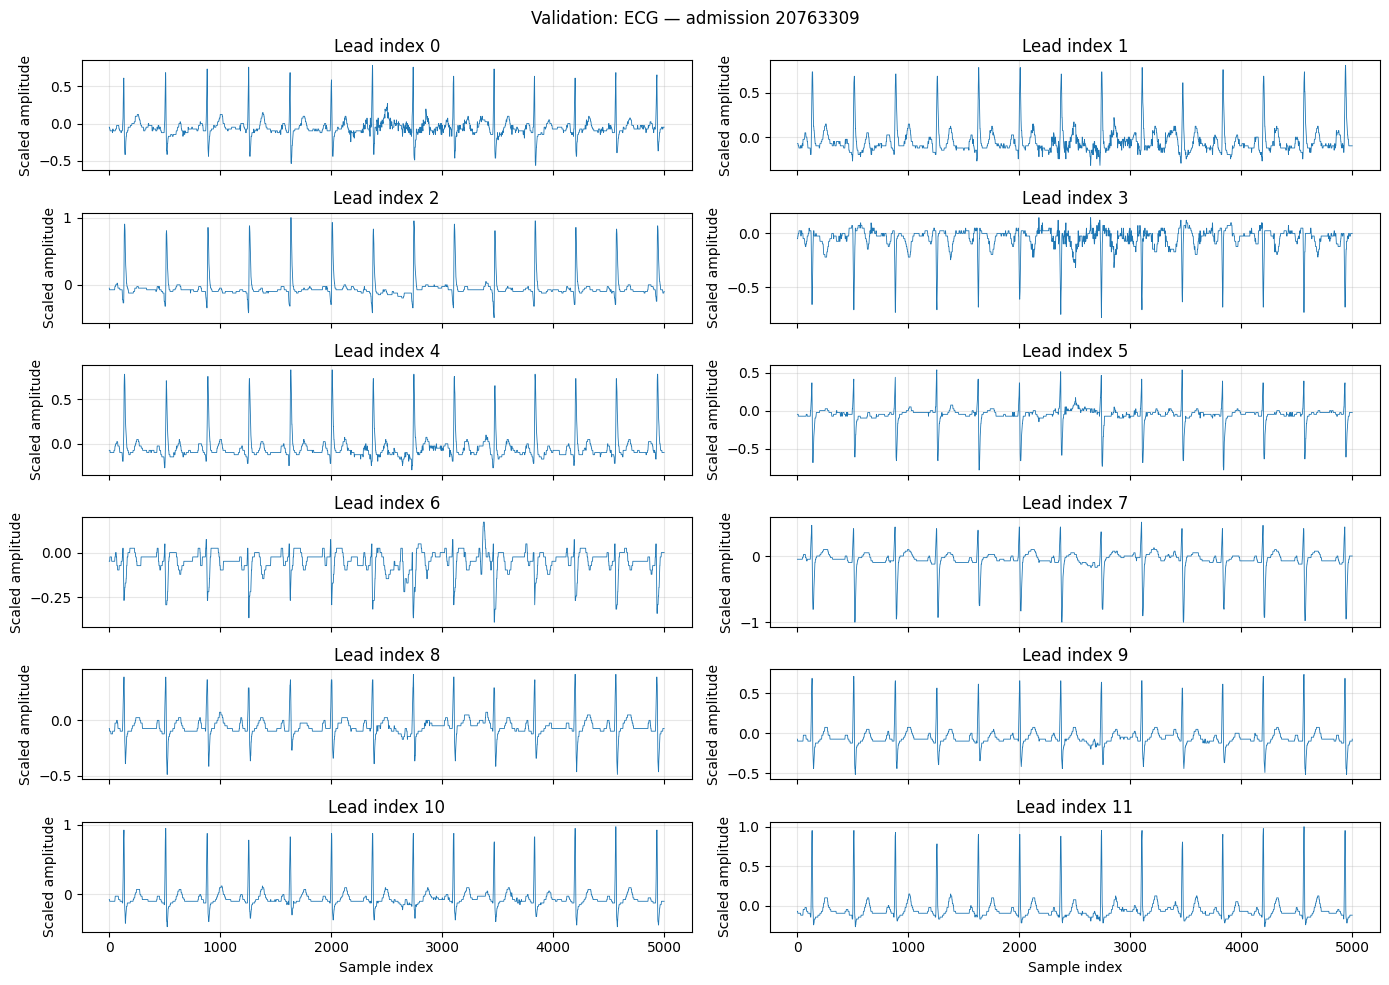

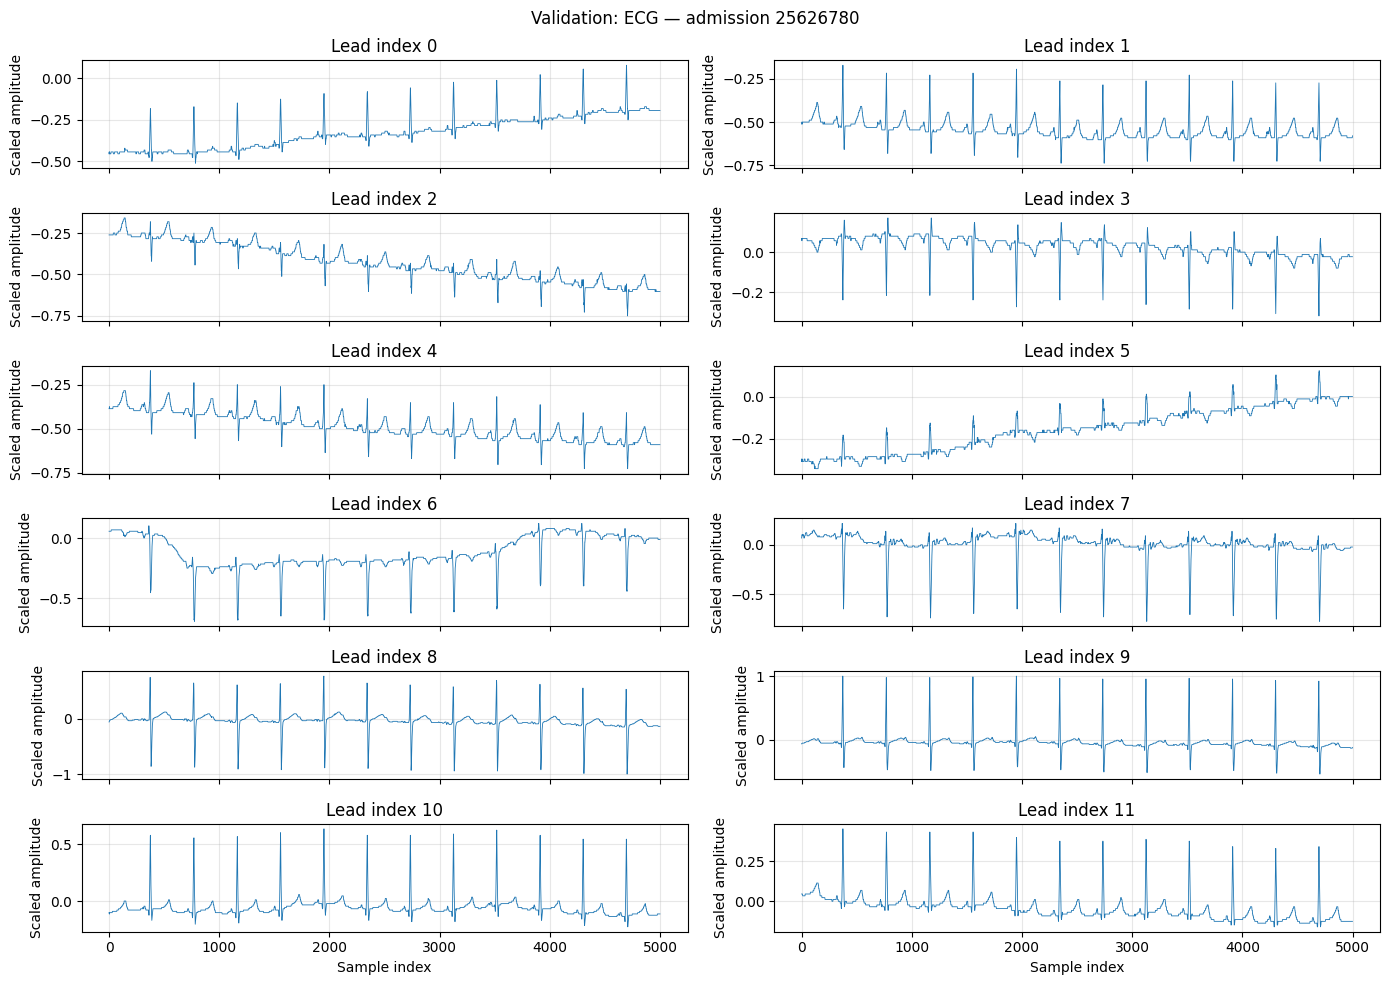

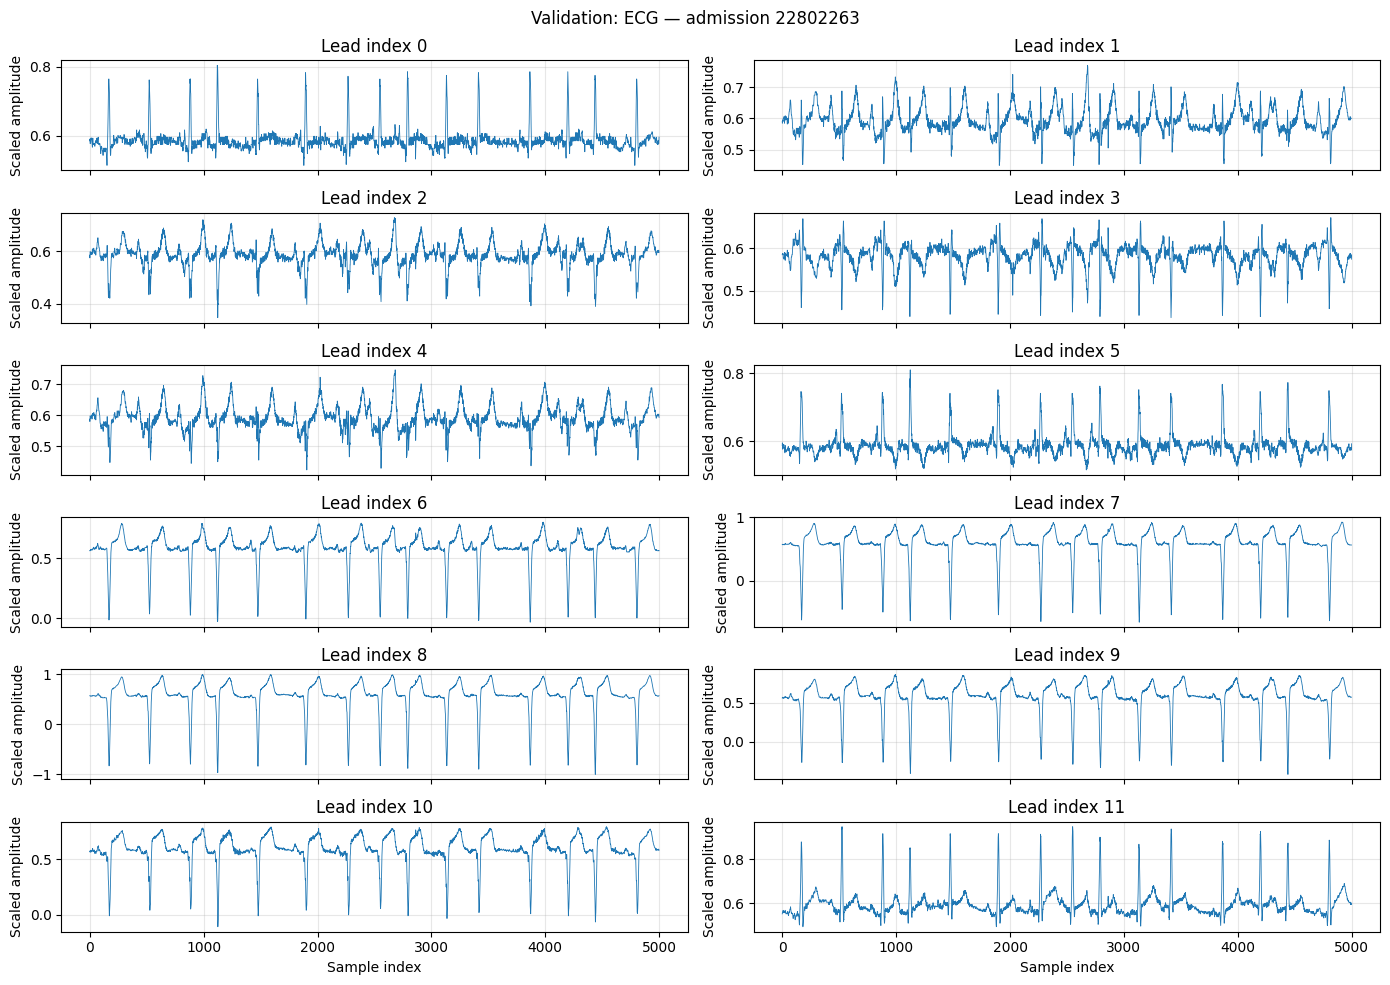

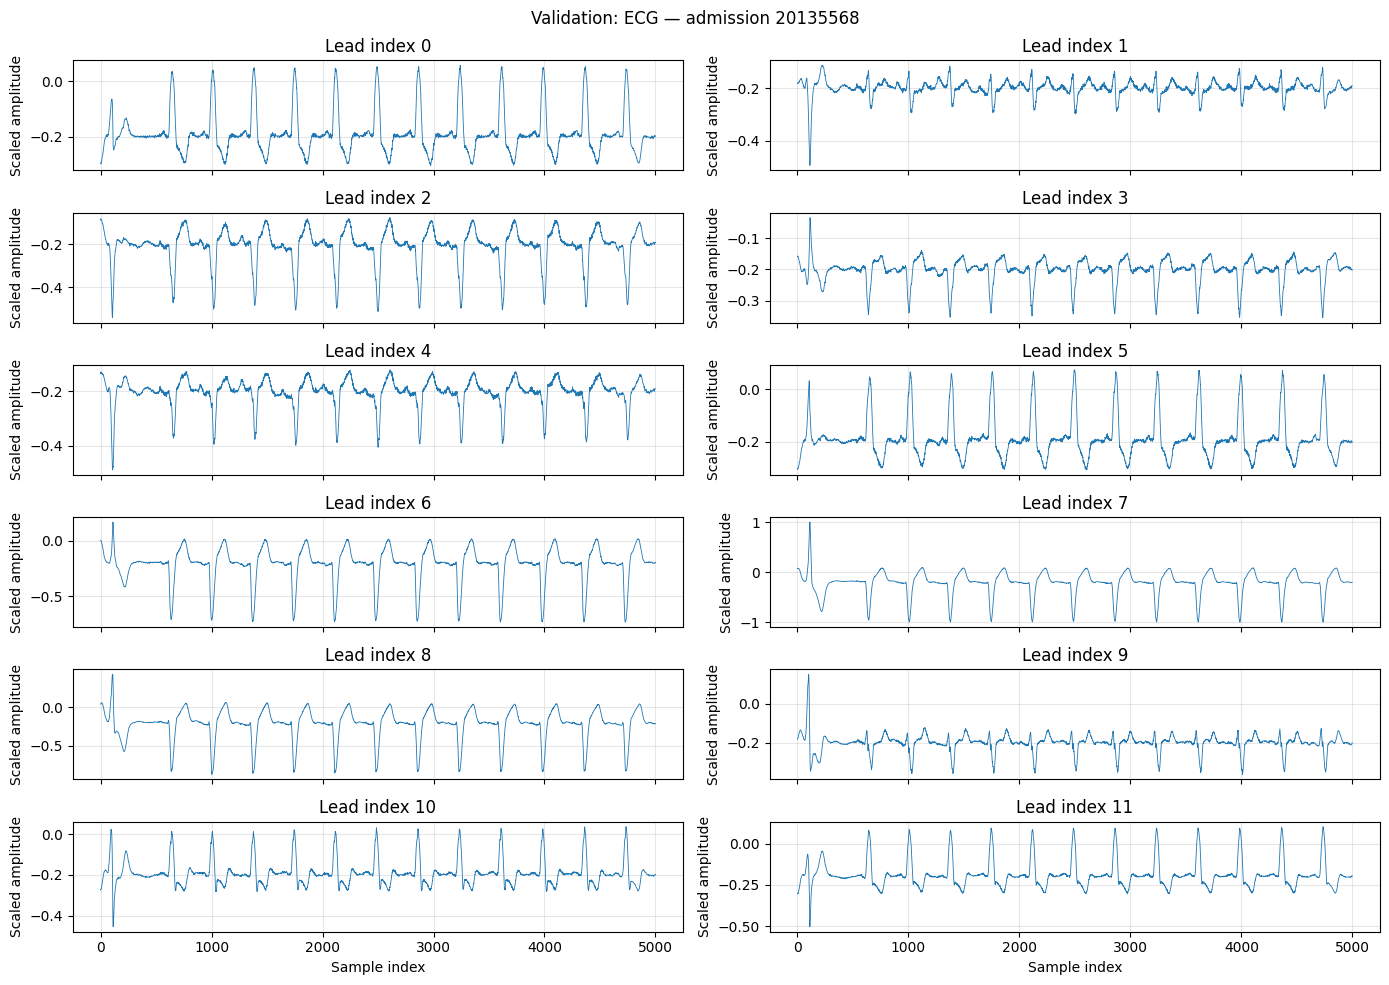

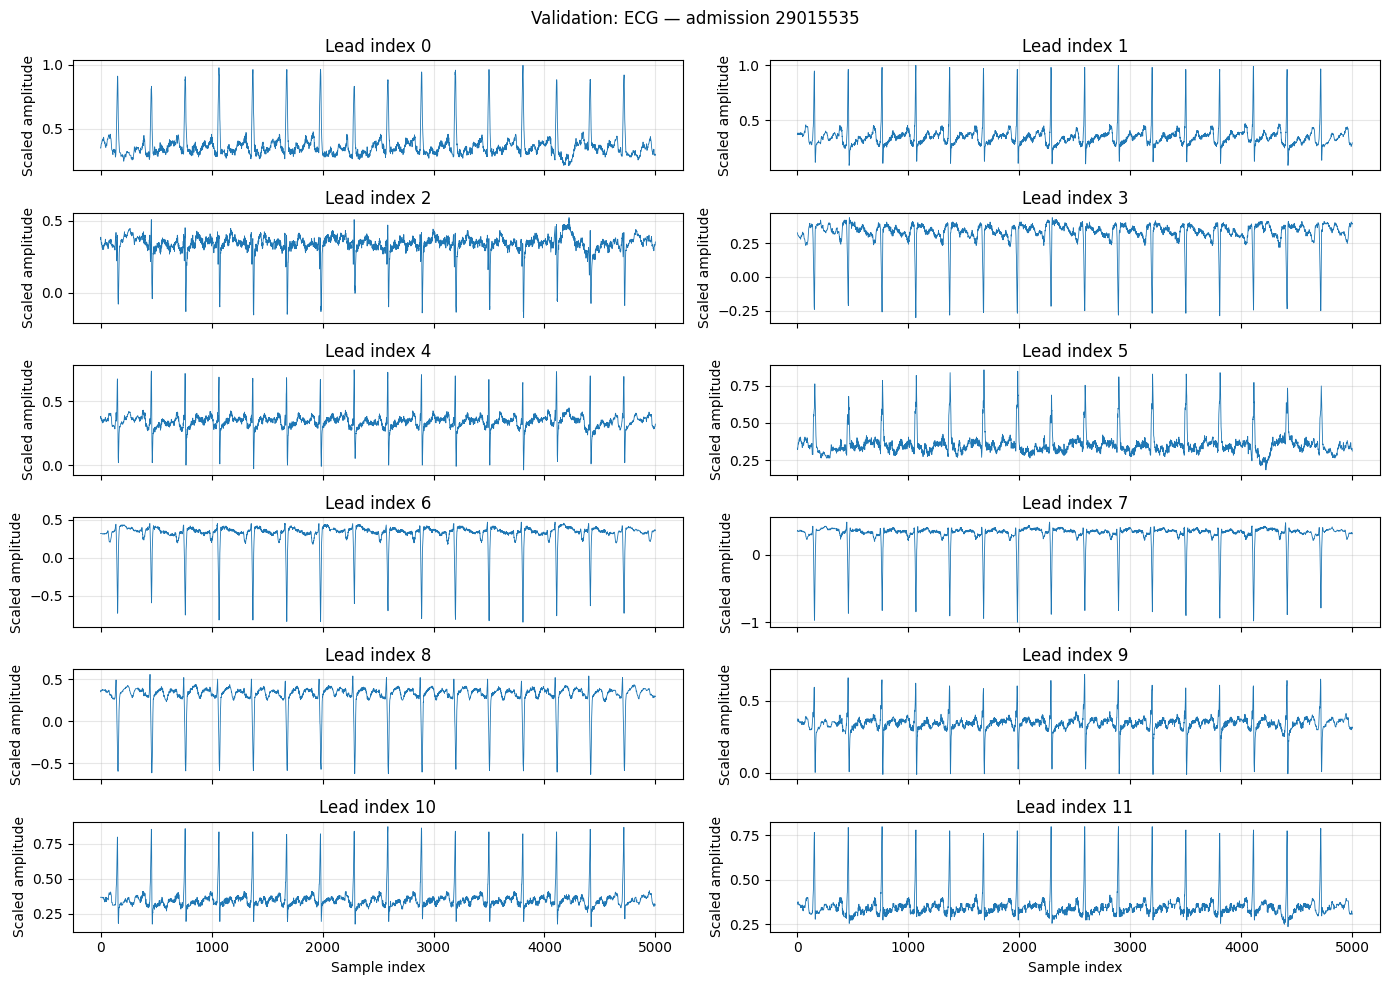

In [13]:
# Display all 12 ECG leads for each of these same five admissions.
for sample in val_samples:
    ecg = sample["ecg"][0].numpy()  # (5000, 12)
    fig, axes = plt.subplots(6, 2, figsize=(14, 10), sharex=True)
    for lead, ax in enumerate(axes.flat):
        ax.plot(ecg[:, lead], linewidth=0.6)
        ax.set_title(f"Lead index {lead}")
        ax.set_ylabel("Scaled amplitude")
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Sample index")
    fig.suptitle(f"Validation: ECG — admission {sample['hadm_id'].item()}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## Test


In [14]:
test_dataset = test_loader.dataset
test_indices = list(range(min(5, len(test_dataset))))

# Retrieve once; reuse these samples in both plots below.
test_samples = [test_dataset[i] for i in test_indices]
test_table = test_dataset.metadata.iloc[test_indices].copy()
test_table["cxr_available"] = [s["modality_mask"][0].item() for s in test_samples]
assert test_table["hadm_id"].tolist() == [s["hadm_id"].item() for s in test_samples]
print("Test admissions:", len(test_dataset))
with pd.option_context("display.max_columns", None):
    display(test_table)


Test admissions: 464


,subject_id,hadm_id,cxr_path,Atelectasis,Cardiomegaly,Edema,Lung Opacity,No Finding,Pleural Effusion,ecg_path,51221,51265,50912,50971,51222,51301,51249,51279,51250,51248,51277,51006,50983,50902,50882,50868,50931,50960,50893,50970,51237,51274,51275,51146,51256,51254,51200,51244,52172,50934,51678,50947,50861,50878,50813,50863,50885,50820,50862,50802,50821,50804,50818,52075,52073,52074,52069,51133,50910,52135,51221_percentile,51265_percentile,50912_percentile,50971_percentile,51222_percentile,51301_percentile,51249_percentile,51279_percentile,51250_percentile,51248_percentile,51277_percentile,51006_percentile,50983_percentile,50902_percentile,50882_percentile,50868_percentile,50931_percentile,50960_percentile,50893_percentile,50970_percentile,51237_percentile,51274_percentile,51275_percentile,51146_percentile,51256_percentile,51254_percentile,51200_percentile,51244_percentile,52172_percentile,50934_percentile,51678_percentile,50947_percentile,50861_percentile,50878_percentile,50813_percentile,50863_percentile,50885_percentile,50820_percentile,50862_percentile,50802_percentile,50821_percentile,50804_percentile,50818_percentile,52075_percentile,52073_percentile,52074_percentile,52069_percentile,51133_percentile,50910_percentile,52135_percentile,label_hadm_id,label,Consolidation,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Pleural Other,Pneumonia,Pneumothorax,Support Devices,array_index,cxr_available
0,11653463,28401574,files/p11/p11653463/s53728075/2ea18533-8ecdc76...,1.0,NaN,NaN,NaN,NaN,NaN,files/p1165/p11653463/s45743342/45743342,29.9,180.0,0.7,4.1,11.1,11.4,37.3,3.65,82.0,30.5,13.7,20.0,141.0,105.0,29.0,11.0,178.0,2.0,8.8,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.9,NaN,NaN,7.47,NaN,4.0,80.0,30.0,40.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.219749,0.335073,0.197234,0.450070,0.430006,0.628439,0.997790,0.379871,0.090398,0.586481,0.332262,0.468565,0.829845,0.787608,0.895372,0.078479,0.799150,0.621271,0.570801,0.694338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.557945,NaN,NaN,0.920958,NaN,0.891749,0.461369,0.832490,0.432313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28401574,1,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0,False
1,13606080,21846096,files/p13/p13606080/s55651307/7d1e94aa-110edb1...,1.0,NaN,0.0,NaN,NaN,0.0,files/p1360/p13606080/s44060073/44060073,45.9,240.0,1.3,4.3,15.1,8.7,32.8,5.16,89.0,29.2,14.5,24.0,140.0,97.0,25.0,22.0,185.0,2.1,8.5,3.5,NaN,NaN,NaN,1.2,64.1,6.9,2.6,25.1,NaN,NaN,NaN,NaN,NaN,NaN,4.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.943559,0.599578,0.668170,0.573538,0.940651,0.416248,0.572921,0.949679,0.367417,0.374046,0.507332,0.583876,0.748340,0.249448,0.626056,0.923634,0.818679,0.733898,0.402296,0.498872,NaN,NaN,NaN,0.978009,0.168243,0.669307,0.845826,0.850201,NaN,NaN,NaN,NaN,NaN,NaN,0.927407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21846096,1,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,True
2,18454638,28898695,files/p18/p18454638/s53597307/33fd267a-091dccc...,1.0,NaN,NaN,NaN,NaN,1.0,files/p1845/p18454638/s43955252/43955252,48.5,298.0,0.9,7.1,16.1,11.5,33.2,5.19,93.0,31.0,12.4,13.0,130.0,99.0,20.0,18.0,126.0,2.1,8.4,3.7,1.1,11.6,113.4,0.5,72.3,7.0,2.4,17.8,NaN,NaN,NaN,NaN,420.0,1327.0,12.4,52.0,1.3,7.07,NaN,-11.0,122.0,21.0,68.0,NaN,NaN,NaN,NaN,NaN,6827.0,NaN,0.976040,0.774744,0.401383,0.983625,0.978008,0.633862,0.675171,0.953596,0.603556,0.670149,0.048112,0.189411,0.085128,0.368749,0.191952,0.731361,0.520389,0.733898,0.356371,0.584818,0.447015,0.290907,0.982845,0.764720,0.331993,0.689525,0.828919,0.696382,NaN,NaN,NaN,NaN,0.97587,0.98836,0.993939,0.103988,0.841488,0.029455,NaN,0.066887,0.618754,0.232225,0.927141,NaN,NaN,NaN,NaN,NaN,0.980078,NaN,28898695,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,2,False
3,16522692,27652514,files/p16/p16522692/s57313388/ea6f2577-4a85820...,-1.0,NaN,NaN,1.0,NaN,-1.0,files/p1652/p16522692/s41052901/41052901,48.0,280.0,1.0,4.1,15.5,8.8,32.4,5.10,94.0,30.5,12.5,9.0,139.0,104.0,20.0,19.0,115.0,NaN,NaN,NaN,NaN,NaN,NaN,1.1,66.2,6.6,2.2,24.0,NaN,NaN,NaN,NaN,NaN

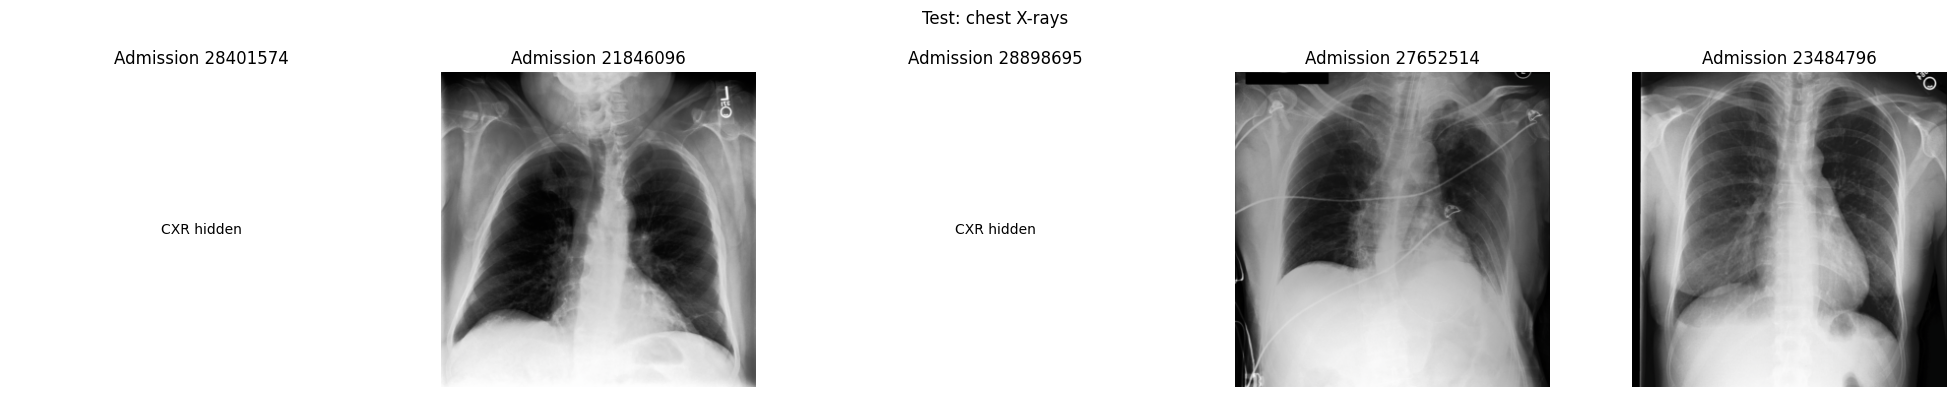

In [15]:
# Undo ImageNet normalization for display only.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(1, len(test_samples), figsize=(20, 4), squeeze=False)
for ax, sample in zip(axes.flat, test_samples):
    if sample["modality_mask"][0].item():
        image = sample["cxr"].numpy().transpose(1, 2, 0)
        ax.imshow(np.clip(image * std + mean, 0, 1))
    else:
        assert not sample["cxr"].any().item()
        ax.text(0.5, 0.5, "CXR hidden", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"Admission {sample['hadm_id'].item()}")
    ax.axis("off")
fig.suptitle("Test: chest X-rays")
plt.tight_layout()
plt.show()
plt.close(fig)


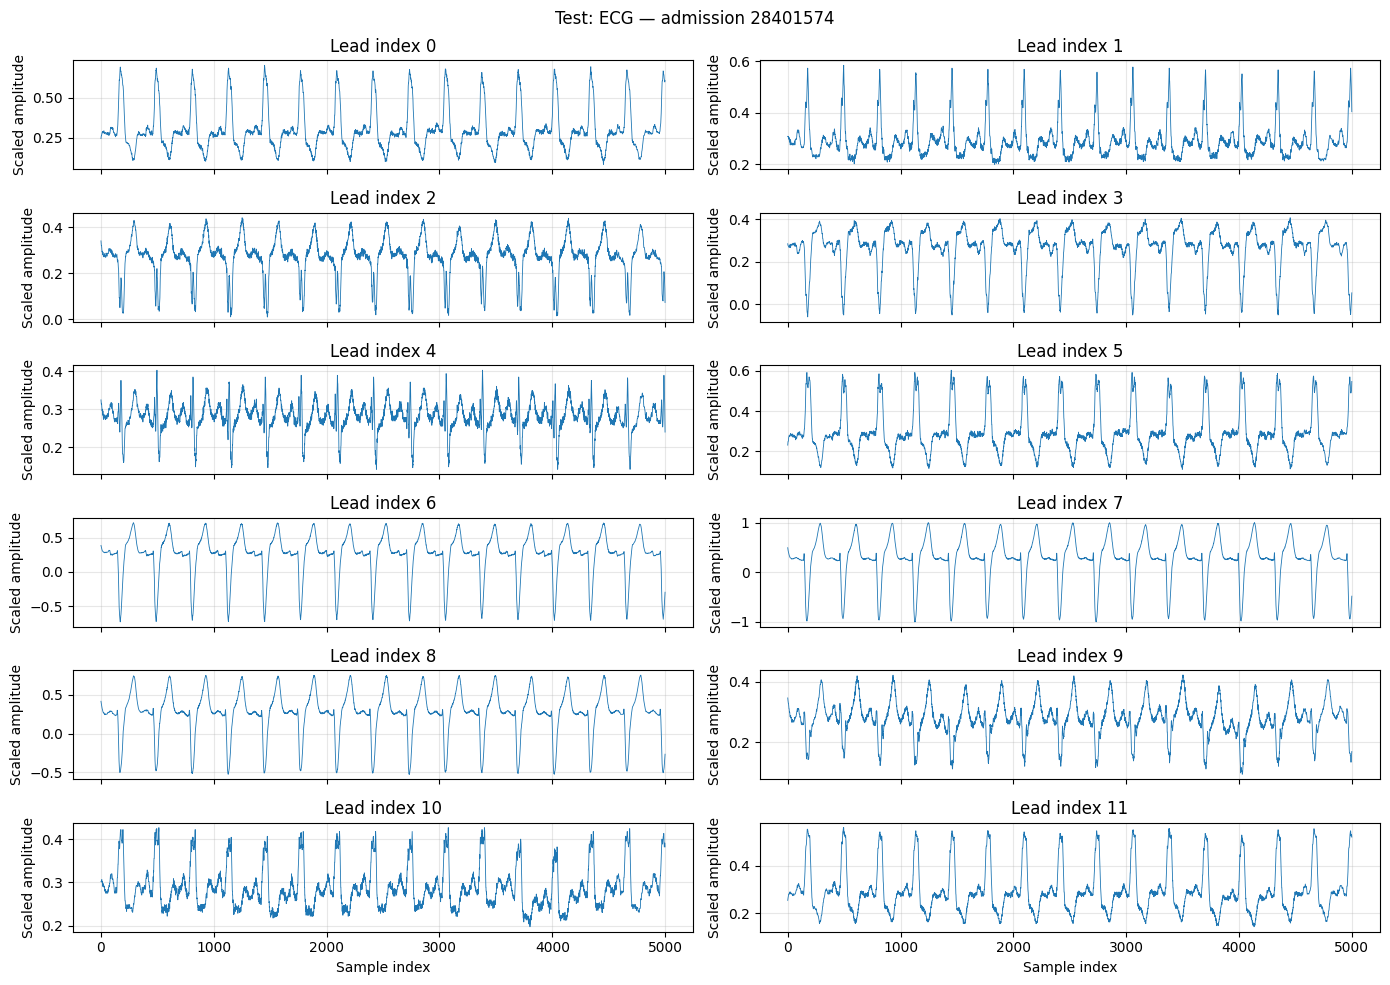

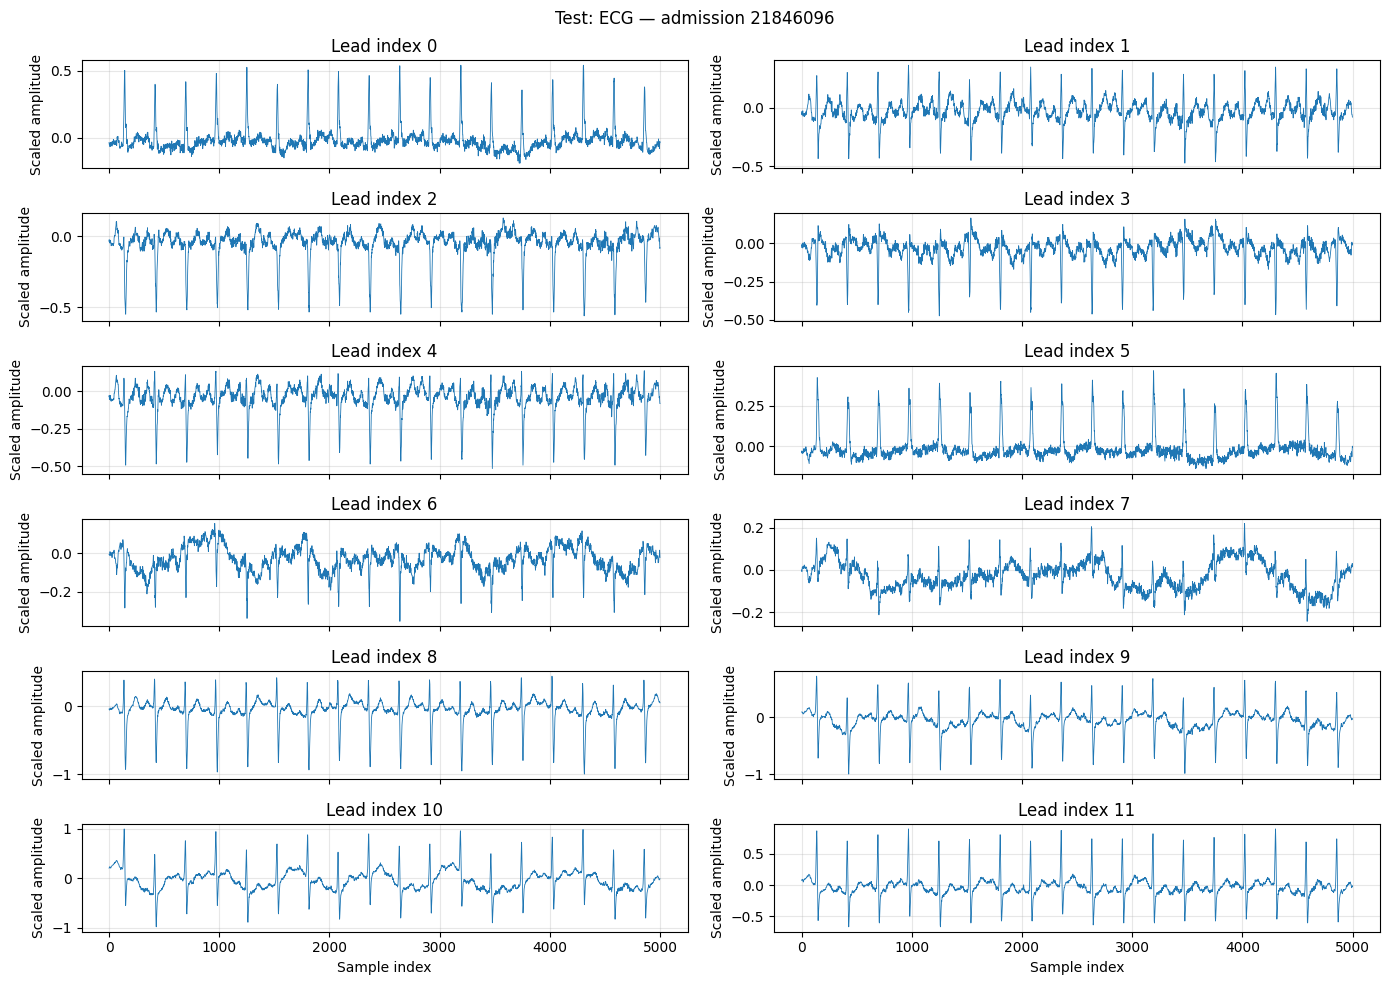

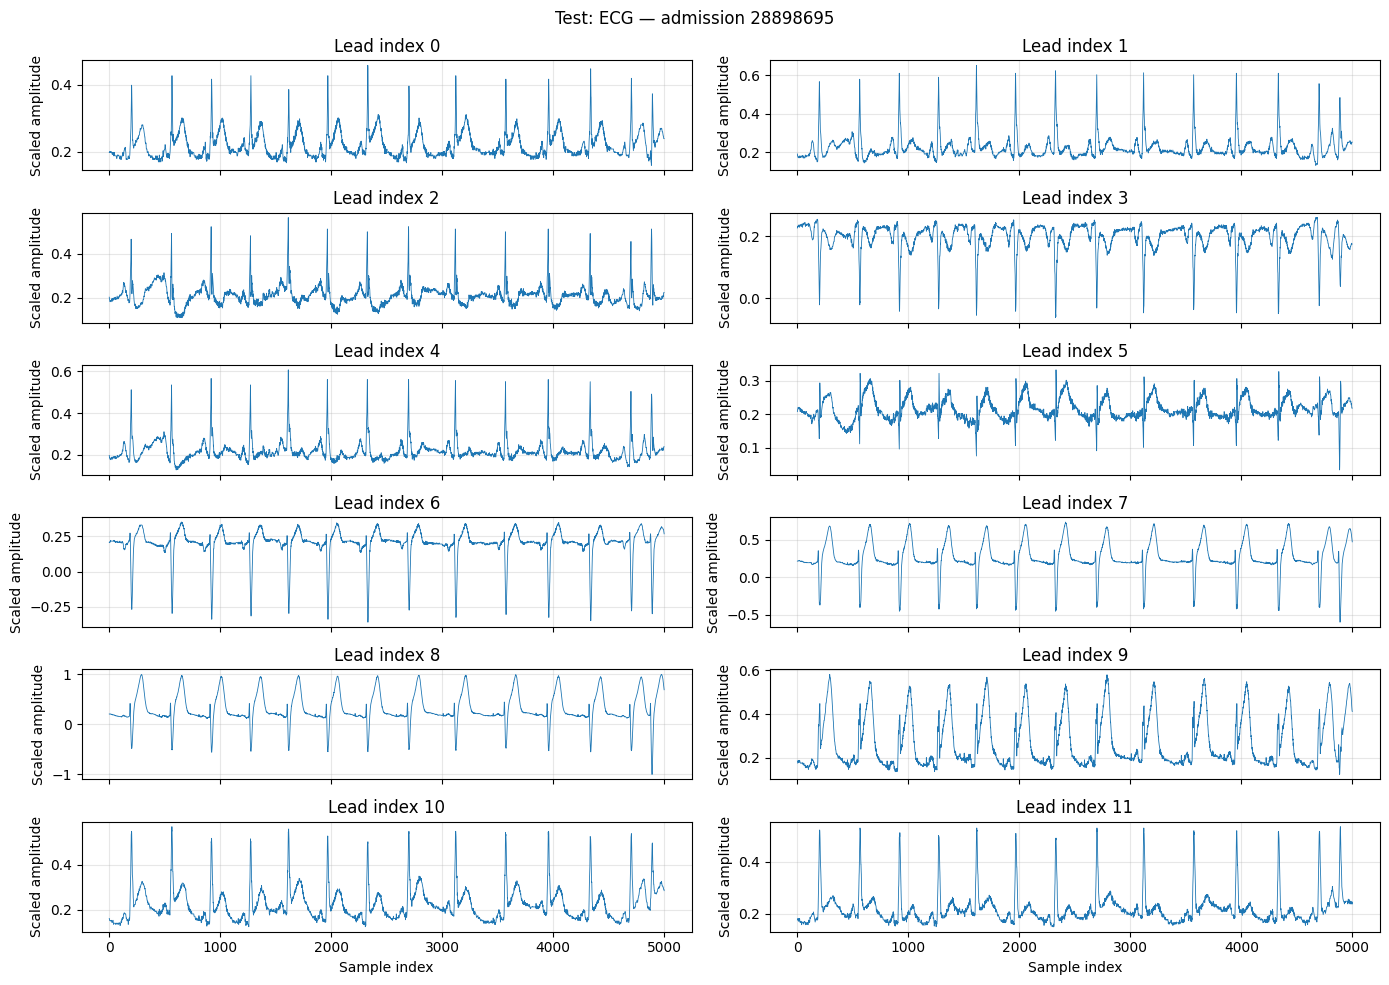

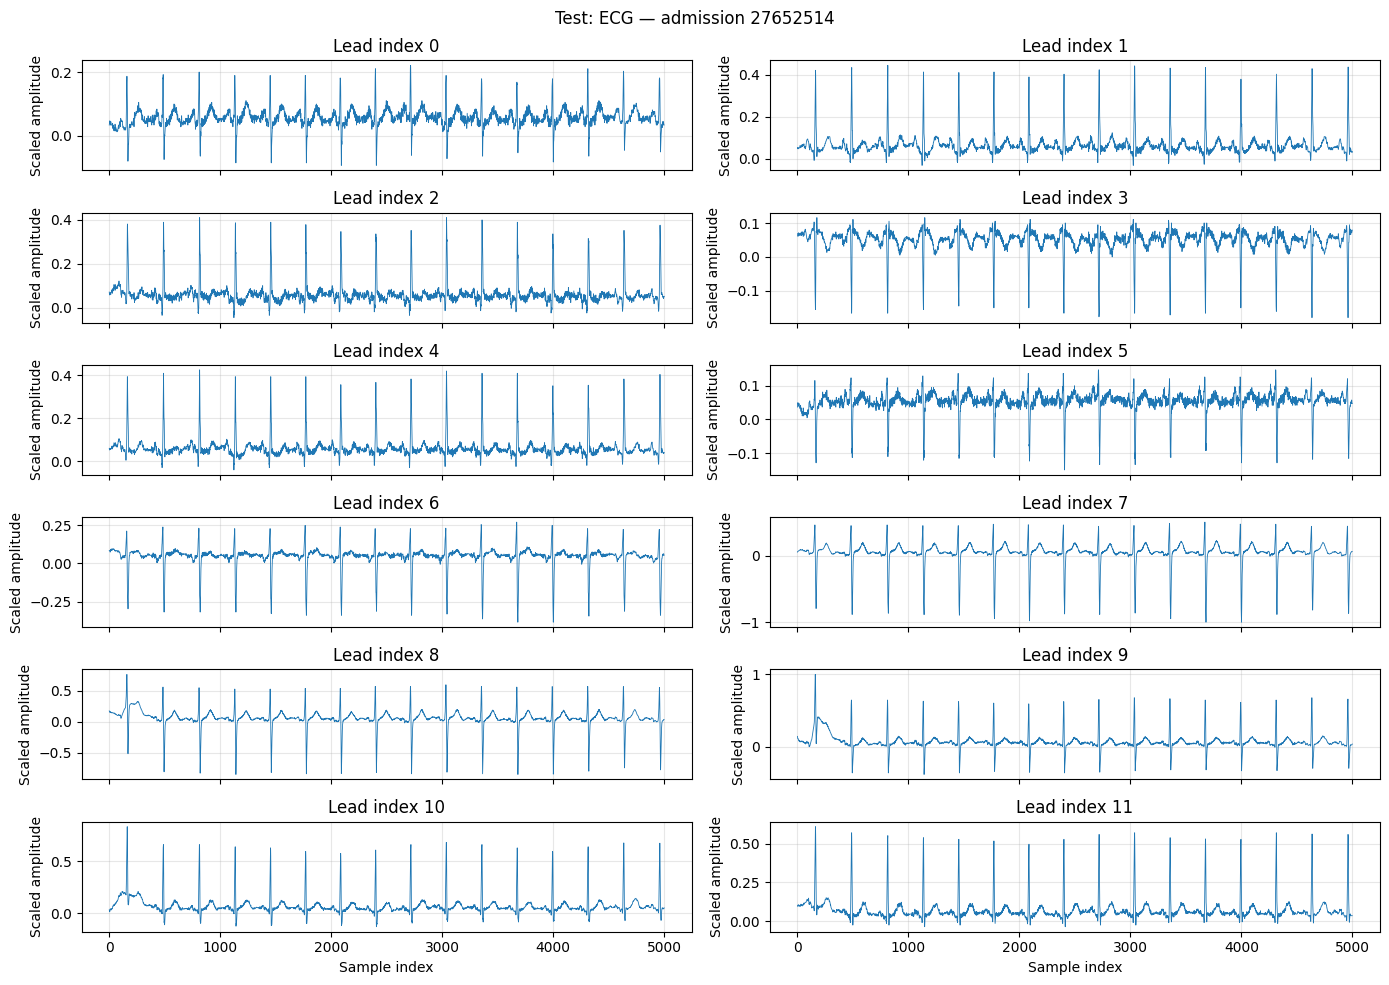

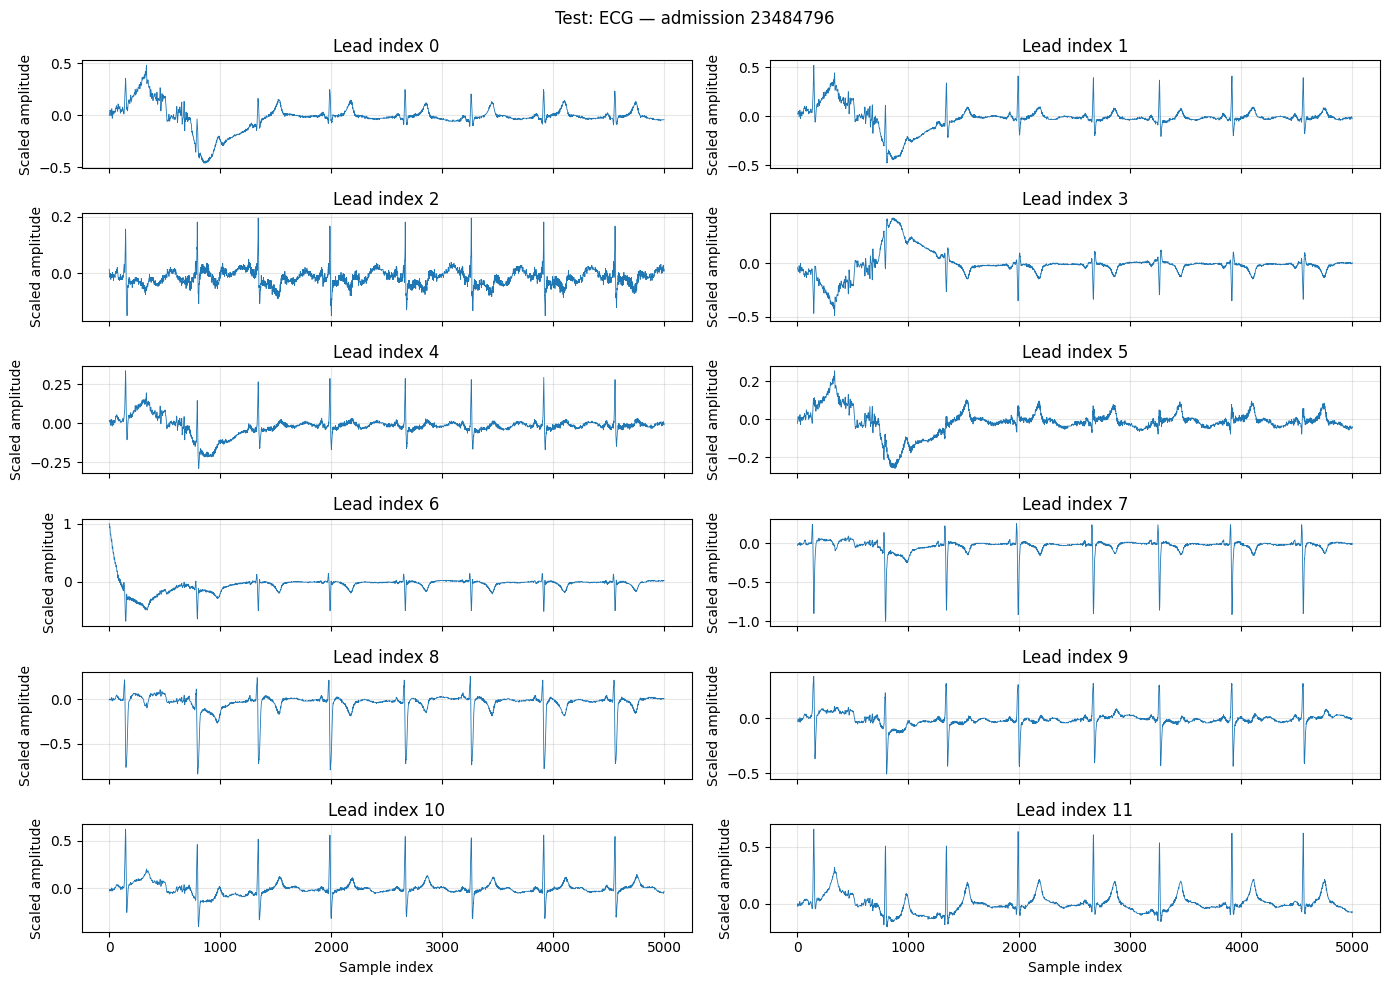

In [16]:
# Display all 12 ECG leads for each of these same five admissions.
for sample in test_samples:
    ecg = sample["ecg"][0].numpy()  # (5000, 12)
    fig, axes = plt.subplots(6, 2, figsize=(14, 10), sharex=True)
    for lead, ax in enumerate(axes.flat):
        ax.plot(ecg[:, lead], linewidth=0.6)
        ax.set_title(f"Lead index {lead}")
        ax.set_ylabel("Scaled amplitude")
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Sample index")
    fig.suptitle(f"Test: ECG — admission {sample['hadm_id'].item()}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
